<a href="https://colab.research.google.com/github/rabiakrann/Ileri-Oruntu-Tanima/blob/main/anomaly%20detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [46]:
from scipy.io import loadmat
import numpy as np

data = loadmat("/content/drive/MyDrive/Colab Notebooks/thyroidori.mat")

X = data["X"]
y = data["y"].ravel().astype(int)
normal, anomaly=X[y==0], X[y==1]

print("Veri boyutu:", X.shape)
print("Sınıf dağılımı:", np.unique(y, return_counts=True))


Veri boyutu: (3772, 6)
Sınıf dağılımı: (array([0, 1]), array([3679,   93]))


In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split


In [48]:
k_values=[2, 3, 5, 7, 10, 15]
seed=42

In [49]:
X_train, rest_normal= train_test_split(normal, train_size=0.6, random_state=seed)
X_rest=np.vstack([rest_normal, anomaly])
y_rest=np.array([0]*len(rest_normal)+[1]*len(anomaly))
X_val, X_test, y_val, y_test=train_test_split(
    X_rest, y_rest, test_size=0.5, random_state=seed, stratify=y_rest
)
print(f"train: {len(X_train)} normal | val: {np.sum(y_val==0)}+{np.sum(y_val==1)}|" f"test: {np.sum(y_test==0)}+{np.sum(y_test==1)} (normal+anomaly)")


train: 2207 normal | val: 736+46|test: 736+47 (normal+anomaly)


In [50]:
mu, sd = X_train.mean(axis=0), X_train.std(axis=0)
X_train, X_val, X_test=(X_train-mu)/sd, (X_val-mu)/sd, (X_test-mu)/sd

In [59]:
def nearest_distances(points, train, k, exclude_self=False):
  result=[]
  for i, p in enumerate(points):
    d=np.sqrt(((train-p)**2).sum(axis=1))
    if exclude_self:
      d[i]=np.inf
    result.append(np.sort(d)[:k])
  return np.array(result)

In [52]:
def d_final(nn, k):
  return nn[:, :k].mean(axis=1)

In [53]:
def predict(scores, th):
  return (scores>th).astype(int)

In [67]:
def confusion(y_true, y_pred):
  tn=fp=fn=tp=0
  for t, p in zip(y_true, y_pred):
    if t==0 and p==0:
      tn+=1
    elif t==0 and p==1:
      fp+=1
    elif t==1 and p==0:
      fn+=1
    else:
      tp+=1
  return tn, fp, fn, tp

In [65]:
def f1_score(tn, fp, fn, tp):
  precision=tp/(tp+fp) if tp+fp else 0
  recall=tp/(tp+fn) if tp+fn else 0
  return 2 * precision*recall/(precision+recall)if precision+recall else 0

In [62]:
kmax=max(k_values)
nn_train=nearest_distances(X_train, X_train, kmax, exclude_self=True)
nn_val=nearest_distances(X_val, X_train, kmax)
nn_test=nearest_distances(X_test, X_train, kmax)

In [68]:
results={}
print(f"\n{'k':>3} {'alpha':>6} {'Th':>7} {'TN':>5} {'FP':>4} {'FN':>4} {'TP':>4} {'F1':>6}")
for k in k_values:
  s_train, s_val, s_test=d_final(nn_train, k), d_final(nn_val, k), d_final(nn_test, k)
  mx, std=s_train.max(), s_train.std()

  alphas=np.arange((s_train.min()-mx)/std, 3.0, 0.1)
  f1s=[f1_score(*confusion(y_val, predict(s_val,mx+a*std))) for a in alphas]
  alpha=alphas[int(np.argmax(f1s))]
  th=mx+alpha*std

  cm=confusion(y_test, predict(s_test, th))
  results[k]=(s_test, th, alpha, cm)
  print(f"{k:>3} {alpha:>6.1f} {th:7.3f} {cm[0]:>5} {cm[1]:>4} {cm[2]:>4} {cm[3]:>4} {f1_score(*cm):6.3f}")


  k  alpha      Th    TN   FP   FN   TP     F1
  2  -28.5   1.534   716   20    9   38  0.724
  3  -27.6   1.867   722   14   10   37  0.755
  5  -27.1   1.915   721   15    8   39  0.772
  7  -26.5   2.060   721   15    8   39  0.772
 10  -25.7   2.399   724   12    9   38  0.784
 15  -25.0   2.555   723   13    8   39  0.788


In [69]:
k=5
tn, fp, fn, tp=results[k][3]
print(f"\nConfusion matrix (test, k={k}, alpha={results[k][2]:.1f})")
print("               pred normal  pred anomaly")
print(f"true normal    TN={tn:<9} FP={fp}")
print(f"true anomaly   FN={fn:<9} TP={tp}")
print(f"F1 = {f1_score(tn, fp, fn, tp):.3f}")


Confusion matrix (test, k=5, alpha=-27.1)
               pred normal  pred anomaly
true normal    TN=721       FP=15
true anomaly   FN=8         TP=39
F1 = 0.772



saved: dfinal_distribution.png


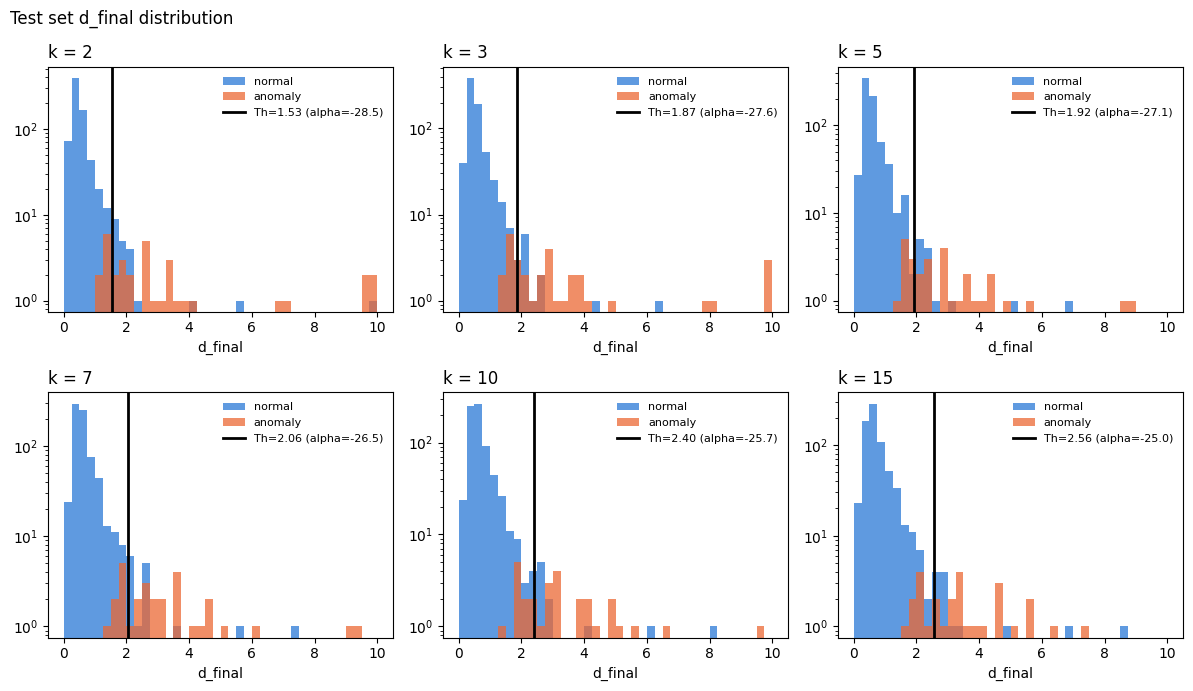

In [70]:
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
bins = np.arange(0, 10.25, 0.25)
for ax, (k, (s_test, th, alpha, _)) in zip(axes.flat, results.items()):
    ax.hist(s_test[y_test == 0], bins=bins, color="#2a78d6", alpha=0.75, label="normal")
    ax.hist(s_test[y_test == 1], bins=bins, color="#eb6834", alpha=0.75, label="anomaly")
    ax.axvline(th, color="black", lw=2, label=f"Th={th:.2f} (alpha={alpha:.1f})")
    ax.set_yscale("log")
    ax.set_title(f"k = {k}", loc="left")
    ax.set_xlabel("d_final")
    ax.legend(fontsize=8, frameon=False)
fig.suptitle("Test set d_final distribution", x=0.01, ha="left")
fig.tight_layout()
fig.savefig("dfinal_distribution.png", dpi=150)
print("\nsaved: dfinal_distribution.png")